### Generación de los datos $Y_k$

Generación de trayectorias con un integrador de **Euler-Maruyama**

Cámara CMOS recogiendo datos con una frecuencia de 20Hz ($\Delta t_{obs}$ = 0.05s) en un lapso de tiempo T = 10s (N = 200 observaciones)

$$ Y_k = X(t_k) + \eta_k, \, \, \eta_k \sim \mathcal{N}(0, \sigma^2_{obs}) $$


donde:
- $X_t$ viene de: $dX_t = v_{flujo}dt + \sqrt{2D}\, dW_t$ 
- $\eta_k$: asociado al error inducido por la PSF y la lectura 
- Tamaño del paso: $\Delta t_{sim}$ = $10^{-4}\text{s}$

Tres regímenes de ruido experimental:

| Régimen  |  $\sigma_{obs}$  | Interpretación |
| :--- | :--- | :--- |
| Limpio | 0.0 ${\mu m}$| Límite ideal de superresolución analítica (No hay ruido)|
| Moderado | 0.02 ${\mu m}$| Precisión típica de algoritmos de ajuste de centroide gaussiano |
| Severo | 0.08 ${\mu m}$| Régimen e baja fluorescencia o fotoblanqueamiento |


#### Artefacto de Ruido en Incrementos Finitos

$$ \frac{\Delta Y_k}{\Delta t_{obs}} = \frac{Y_{k+1} - Y_{k}}{\Delta t_{obs}} = \frac{X_{k+1} - X_k}{\Delta t_{obs}} + \frac{\eta_{k+1} - \eta_k}{\Delta t_{obs}}$$

$\frac{\eta_{k+1} - \eta_k}{\Delta t_{obs}}$ introduce una correlación serial negativa espuria entre pasos contiguos y multiplica la varianza del sensor por $(\frac{1}{\Delta t_{obs}})^2 = (\frac{1}{ 0.05})^2 = 400$.

Correlación negativa: 

$$\text{Cov}(\Delta \eta_k, \Delta \eta_{k+1}) = \text{Cov}(\eta_{k+1} - \eta_k, \eta_{k+2} - \eta_{k+1}) = \text{Cov}(\eta_{k+1}, \eta_{k+2}) - \text{Cov}(\eta_{k+1}, \eta_{k+1}) - \text{Cov}(\eta_k,\eta_{k+2}) + \text{Cov}(\eta_k, \eta_{k+1})$$

La covarianza en instantes distintos es 0 por ser el ruido independiente, por lo que nos quedamos únicamente con el término en $\eta_{k+1}, \eta_{k+1}$, por lo que acabamos con:

$$ \text{Cov}(\Delta \eta_k, \Delta \eta_{k+1}) = -\text{Cov}(\eta_{k+1},\eta_{k+1}) = -\sigma^2_{obs} < 0$$

**Aplicar una regresión directa sobre los incrementos sobreestiman la difusión $\sigma$ real, confundiendo el desenfoque de los píxeles con agitación térmica molecular.**

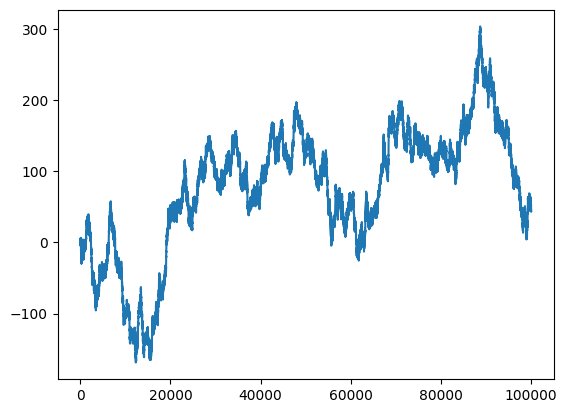

In [ ]:
import numpy as np 

T = 10               # Tiempo en segundos total usados
dt_sim = 1e-4        # Tamaño del paso asociado a la discretización del proceso
dt_obs = 0.05        # Tamaño del paso temporal, asociado a la frecuencia (20 Hz)

# Valores aún por determinar
v_flujo = 1            # Fuerza externa generada por el flujo
D = 0.5                # Término de la difusión 
sigma = np.sqrt(2*D)   # σ = sqrt(2D) = 1

# Euler-Maruyama (X_t)
N_sim = int((T/dt_sim))    # Numero de pasos del proceso para generar 
dW = np.random.normal(loc=0, scale=np.sqrt(sigma), size = N_sim)    # ruido blanco, procedente del proceso browniano
dx = v_flujo * dt_sim + sigma * dW     # dX = \mu * dt + \sigma*dW  (Langevin Sobreamortiguado)
X_continuo = np.concatenate([[0],np.cumsum(dx)])   # Trayectoria empezando en 0 y evolucionando en el tiempo según la ecuación diferencial

import matplotlib.pyplot as plt
plt.plot(X_continuo)